# 06 — Dependência de provedores domésticos vs. estrangeiros

**Pergunta:** as empresas resolvem seus domínios exclusivamente por provedores do próprio país, exclusivamente por provedores de outros países, ou por uma combinação? Como isso varia por país/bloco de origem?

**Definições (por empresa, nível de país)** — $H$ = país da sede (CompaniesMarketCap, ISO-2); $C$ = conjunto de países dos grupos controladores dos seus provedores (`dp_as_country_code`):
- **domestic-only:** todos os provedores são de $H$.
- **foreign-only:** nenhum provedor é de $H$.
- **mixed:** há provedor de $H$ *e* de outros países.

**Blocos:** US, EU (UE-27), BRICS (membros plenos desde 2025: BR, RU, IN, CN, ZA, EG, ET, IR, AE, ID), Others. A sensibilidade usa o BRICS de 5 membros e uma definição *intrabloco* de "doméstico".

**Escopo:** apenas IPv4. O país do provedor é a **jurisdição do controlador**, não a localização dos servidores (relevante para anycast).

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch
from IPython.display import display

from src.analysis_utils import *

set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.width", 200)
MIN_N = 30   # n mínimo de empresas para um recorte por país

v4, cp, comp = prepare()   # IPv4 -> (empresa, provedor) com peso fracionado -> 1 linha por empresa
print(f"{len(comp):,} empresas | {len(v4):,} linhas IPv4 | {cp['provider'].nunique():,} grupos de provedores")

# auditoria: registros WHOIS cujo país é o código regional "EU" (país não resolvido)
unres = cp[cp["provider_cc"] == "EU"]
print(f"Provedores com país 'EU' não resolvido: {unres['provider'].nunique()} grupos, "
      f"{unres['rank'].nunique()} empresas (tratados como estrangeiros na classificação por país)")
print("Países de origem distintos:", comp["home"].nunique())

10,283 empresas | 44,069 linhas IPv4 | 1,083 grupos de provedores
Provedores com país 'EU' não resolvido: 1 grupos, 5 empresas (tratados como estrangeiros na classificação por país)
Países de origem distintos: 75


## 1. Distribuição global e por bloco

In [2]:
g = prop_ci_table(comp.assign(all="All"), "all", "dependence_type", DEP_ORDER).set_index("dependence_type")
g["pct_revenue"] = 100 * comp.groupby("dependence_type")["revenue_ttm"].sum().reindex(DEP_ORDER) / comp["revenue_ttm"].sum()
display(g[["k", "n", "pct", "lo", "hi", "pct_revenue"]])
save_table(g, "dep_global")

# por bloco: contagem (com IC de Wilson) e receita
pb = prop_ci_table(comp, "home_bloc", "dependence_type", DEP_ORDER)
display(pb.pivot(index="home_bloc", columns="dependence_type", values="pct").reindex(BLOCS)[DEP_ORDER])
save_table(pb.set_index(["home_bloc", "dependence_type"]), "dep_by_bloc")

# associação bloco x tipo de dependência
ct = pd.crosstab(comp["home_bloc"], comp["dependence_type"]).reindex(index=BLOCS, columns=DEP_ORDER)
chi2, p, dof, V = cramers_v(ct)
print(f"qui-quadrado = {chi2:,.1f} (gl={dof}), p = {p:.2e}, V de Cramér = {V:.3f}")

,k,n,pct,lo,hi,pct_revenue
dependence_type,,,,,,
domestic-only,4634,10283,45.06,44.11,46.03,55.82
mixed,518,10283,5.04,4.63,5.48,8.01
foreign-only,5131,10283,49.90,48.93,50.86,36.17


dependence_type,domestic-only,mixed,foreign-only
home_bloc,,,
US,80.04,0.61,19.34
EU,30.64,11.62,57.74
BRICS,41.06,3.75,55.19
Others,24.10,6.13,69.77


qui-quadrado = 2,603.2 (gl=6), p = 0.00e+00, V de Cramér = 0.356


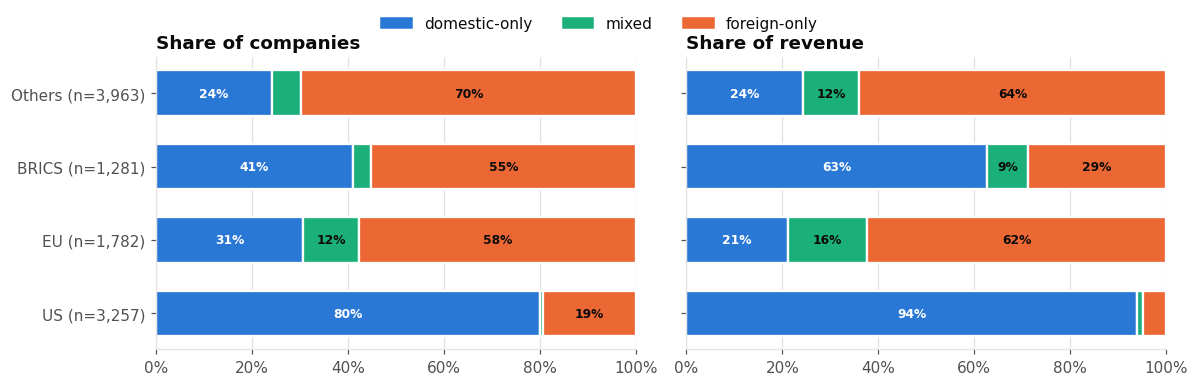

In [3]:
pct_c = (ct.div(ct.sum(axis=1), axis=0) * 100).reindex(BLOCS)
rv = comp.pivot_table(index="home_bloc", columns="dependence_type", values="revenue_ttm", aggfunc="sum").reindex(index=BLOCS, columns=DEP_ORDER).fillna(0)
pct_r = rv.div(rv.sum(axis=1), axis=0) * 100

lab = [f"{b} (n={ct.loc[b].sum():,})" for b in BLOCS]
pct_c.index, pct_r.index = lab, lab

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
stacked_hbar(axes[0], pct_c, DEP_COLOR)
axes[0].set_title("Share of companies")
stacked_hbar(axes[1], pct_r, DEP_COLOR)
axes[1].set_title("Share of revenue")
handles = [Patch(color=DEP_COLOR[c], label=c) for c in DEP_ORDER]
fig.legend(handles=handles, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.04), frameon=False)
fig.tight_layout()
save_fig(fig, "fig_dep_bloc")
plt.show()

## 2. Por país de origem

dependence_type,domestic-only,mixed,foreign-only
BM (n=39),0.00,0.00,100.00
GR (n=43),0.00,2.33,97.67
LU (n=34),0.00,2.94,97.06
NZ (n=52),3.85,0.00,96.15
IE (n=39),2.56,5.13,92.31
GB (n=462),5.41,2.60,91.99
DK (n=61),4.92,3.28,91.80
AU (n=354),3.95,6.50,89.55
SG (n=76),3.95,7.89,88.16
IN (n=571),10.16,1.93,87.92


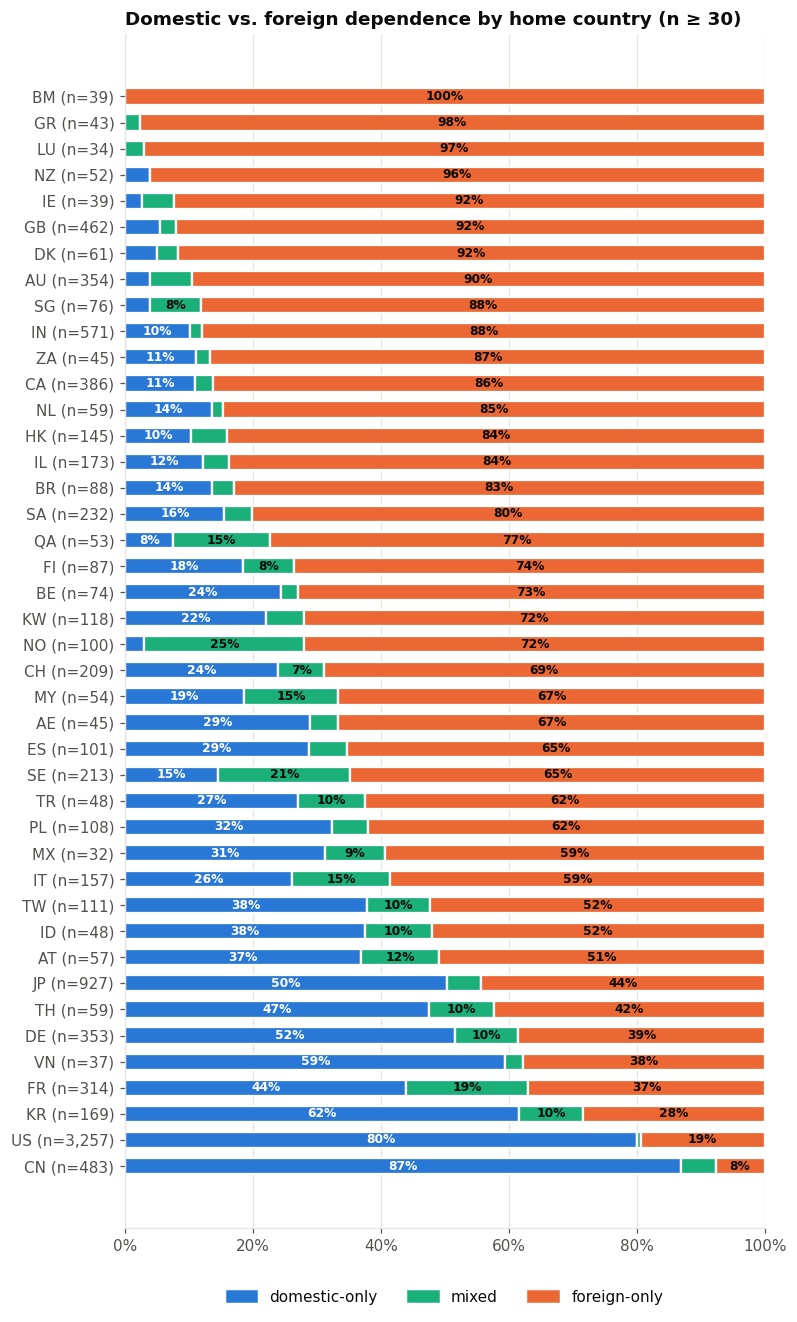

In [4]:
cn = comp["home"].value_counts()
countries = cn[cn >= MIN_N].index
pc = prop_ci_table(comp[comp["home"].isin(countries)], "home", "dependence_type", DEP_ORDER)
wide = pc.pivot(index="home", columns="dependence_type", values="pct")[DEP_ORDER].sort_values("foreign-only", ascending=False)
wide.index = [f"{c} (n={cn[c]:,})" for c in wide.index]
display(wide)
save_table(pc.set_index(["home", "dependence_type"]), "dep_by_country")

fig, ax = plt.subplots(figsize=(7.5, 0.3 * len(wide) + 1.5))
stacked_hbar(ax, wide, DEP_COLOR)
ax.set_title(f"Domestic vs. foreign dependence by home country (n ≥ {MIN_N})")
ax.legend(handles=[Patch(color=DEP_COLOR[c], label=c) for c in DEP_ORDER], loc="upper center",
          ncol=3, bbox_to_anchor=(0.5, -0.04), frameon=False)
save_fig(fig, "fig_dep_country")
plt.show()

## 3. Para onde vai a dependência? (origem → destino)

Para cada grupo de origem, a fração média do "peso" das empresas (atribuição fracionada) que vai para provedores de cada destino. As linhas somam 100%.

provider_bloc,US,EU,BRICS,Others
home_bloc,,,,
US,80.42,17.39,0.03,2.16
EU,45.38,52.21,0.04,2.38
BRICS,42.16,12.51,43.27,2.06
Others,58.67,10.94,1.46,28.93


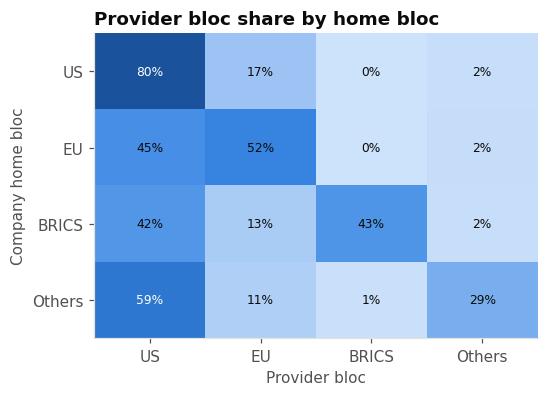

In [5]:
def heat(ax, M, fmt="{:.0f}", title=""):
    im = ax.imshow(M.to_numpy(), cmap=seq_cmap(), vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(M.shape[1]))
    ax.set_xticklabels(M.columns)
    ax.set_yticks(range(M.shape[0]))
    ax.set_yticklabels(M.index)
    ax.grid(False)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.iat[i, j]
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=8,
                    color="white" if v > 55 else INK)
    ax.set_title(title)
    return im


# bloco -> bloco
Mb = cp.pivot_table(index="home_bloc", columns="provider_bloc", values="weight", aggfunc="sum").reindex(index=BLOCS, columns=BLOCS).fillna(0)
Mb = Mb.div(Mb.sum(axis=1), axis=0) * 100
display(Mb)
save_table(Mb, "dep_matrix_bloc")

fig, ax = plt.subplots(figsize=(5.2, 3.6))
heat(ax, Mb.rename(index=lambda b: f"{b}", columns=lambda b: f"{b}"), "{:.0f}%", "Provider bloc share by home bloc")
ax.set_xlabel("Provider bloc")
ax.set_ylabel("Company home bloc")
save_fig(fig, "fig_dep_matrix_bloc")
plt.show()

dest,US,DE,JP,CN,FR,AT,CA,KR,Other
home,,,,,,,,,
US,80.42,15.99,0.03,0.03,0.42,0.73,1.95,0.03,0.40
JP,45.46,0.47,53.42,0.00,0.00,0.10,0.12,0.00,0.44
IN,63.15,19.98,0.04,0.00,0.74,0.54,0.90,0.35,14.29
CN,7.73,1.24,0.00,90.33,0.00,0.00,0.12,0.00,0.59
GB,70.04,15.26,0.00,0.00,0.65,2.03,1.40,0.00,10.63
CA,69.63,15.93,0.00,0.00,0.86,0.46,12.43,0.13,0.56
AU,84.96,5.65,0.00,0.00,0.42,0.00,0.56,0.00,8.40
DE,32.43,56.70,0.00,0.07,0.81,7.79,0.28,0.00,1.91
FR,37.75,2.44,0.00,0.00,53.61,2.78,0.00,0.00,3.43


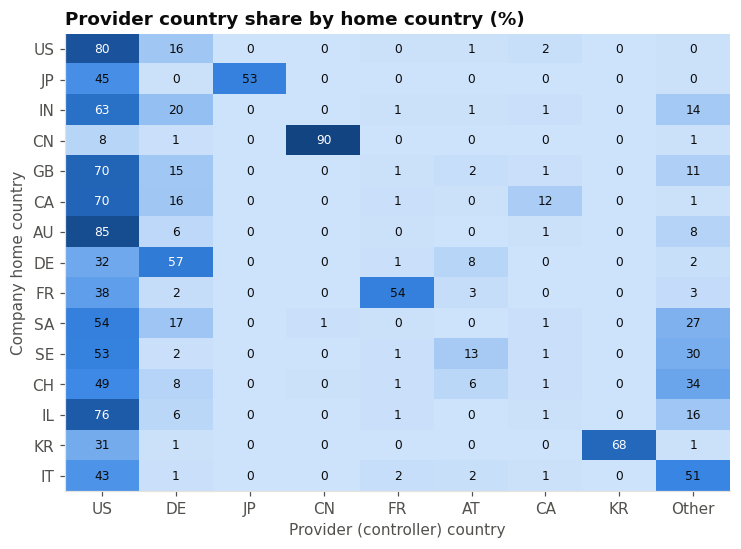

In [6]:
# país -> país: países de origem (n >= MIN_N, 15 maiores) x 8 principais países de provedores (+ Other)
top_home = cn[cn >= MIN_N].head(15).index.tolist()
top_prov = cp.groupby("provider_cc")["weight"].sum().sort_values(ascending=False).head(8).index.tolist()
t = cp[cp["home"].isin(top_home)].copy()
t["dest"] = t["provider_cc"].where(t["provider_cc"].isin(top_prov), "Other")
Mc = t.pivot_table(index="home", columns="dest", values="weight", aggfunc="sum").reindex(top_home).fillna(0)
Mc = Mc.reindex(columns=top_prov + ["Other"], fill_value=0)
Mc = Mc.div(Mc.sum(axis=1), axis=0) * 100
display(Mc)
save_table(Mc, "dep_matrix_country")

fig, ax = plt.subplots(figsize=(7.8, 5.4))
heat(ax, Mc, "{:.0f}", "Provider country share by home country (%)")
ax.set_xlabel("Provider (controller) country")
ax.set_ylabel("Company home country")
save_fig(fig, "fig_dep_matrix_country")
plt.show()

In [7]:
# quais são os provedores estrangeiros mais usados por cada bloco de origem?
rows = []
for b in BLOCS:
    f = cp[(cp["home_bloc"] == b) & (cp["provider_cc"] != cp["home"])]
    s = f.groupby(["provider", "provider_cc"])["weight"].sum().sort_values(ascending=False)
    s = 100 * s / s.sum()
    for (prov_, cc), v in s.head(5).items():
        rows.append({"home_bloc": b, "provider": prov_, "provider_cc": cc, "% of foreign weight": v})
foreign_top = pd.DataFrame(rows).set_index(["home_bloc", "provider"])
display(foreign_top)
save_table(foreign_top, "dep_top_foreign_providers")

provider_cc  % of foreign weight
home_bloc provider                                                                           
US        Host Europe GmbH                                            DE                79.85
          easyDNS Technologies, Inc.                                  CA                 3.84
          ipcom GmbH                                                  AT                 3.67
          CIRA Canadian Internet Registration Authority A...          CA                 3.55
          Tucows.com Co.                                              CA                 2.20
EU        Cloudflare, Inc.                                            US                24.27
          DigiCert                                                    US                12.06
          Microsoft Corporation                                       US                 9.53
          Amazon.com, Inc.                                            US                 9.19
          Akamai                                                      US                 6.58
BRICS     Cloudflare, Inc.                                            US                28.11
          Amazon.com, Inc.                                            US                18.28
          Host Europe GmbH                                            DE                16.93
          Akamai                                                      US                 8.45
          Microsoft Corporation                                       US                 4.95
Others    Cloudflare, Inc.                                            US                29.12
          Amazon.com, Inc.                                            US                21.80
          Host Europe GmbH                                            DE                 8.90
          DigiCert                                                    US                 8.21
          Akamai                                                      US                 7.52

In [8]:
# exposição aos EUA como país provedor (empresas sediadas fora dos EUA)
gus = cp.assign(us=cp["provider_cc"].eq("US")).groupby("rank")["us"]
us = pd.DataFrame({"any_US": gus.any(), "only_US": gus.all()}).join(comp[["home", "home_bloc"]])
nonus = us[us["home"] != "US"]
tab_us = (nonus.groupby("home_bloc")[["any_US", "only_US"]].mean() * 100).reindex(["EU", "BRICS", "Others"])
tab_us.loc["All non-US"] = nonus[["any_US", "only_US"]].mean() * 100
tab_us["n"] = list(nonus.groupby("home_bloc").size().reindex(["EU", "BRICS", "Others"])) + [len(nonus)]
display(tab_us)
save_table(tab_us, "dep_us_exposure")

,any_US,only_US,n
home_bloc,,,
EU,51.52,40.68,1782
BRICS,44.50,40.28,1281
Others,62.00,56.14,3963
All non-US,56.15,49.33,7026


## 4. Sensibilidade

Variantes: (i) "doméstico" = mesmo **bloco** (só US/EU/BRICS); (ii) **sem de-para** (organização/país como registrados); (iii) **BRICS de 5 membros**; (iv) **sem domicílios offshore** (Bermudas, Ilhas Cayman, BVI, Bahamas, Guernsey, Jersey, Ilha de Man, Gibraltar), onde sede ≠ operação; (v) sem as empresas com provedor de país "EU" não resolvido.

In [9]:
OFFSHORE = {"BM", "KY", "VG", "BS", "GG", "JE", "IM", "GI"}
cp_nd = company_provider(v4, "as_org", "as_country_code")
comp_nd = company_table(v4, cp_nd)
v4c = load_ipv4(brics=BRICS_CORE)
cp_c = company_provider(v4c, brics=BRICS_CORE)
comp_c = company_table(v4c, cp_c)
bad_ranks = set(unres["rank"])

variants = {
    "Baseline": (comp, "dependence_type"),
    "Intra-bloc 'domestic'": (comp, "dependence_bloc"),
    "No de-para": (comp_nd, "dependence_type"),
    "BRICS = 5 original members": (comp_c, "dependence_type"),
    "Excluding offshore domiciles": (comp[~comp["home"].isin(OFFSHORE)], "dependence_type"),
    "Excluding unresolved 'EU' country": (comp[~comp.index.isin(bad_ranks)], "dependence_type"),
}
rows = []
for name, (df_, col) in variants.items():
    t = df_.dropna(subset=[col])
    p = pd.crosstab(t["home_bloc"], t[col], normalize="index").mul(100)
    for b in BLOCS:
        if b in p.index:
            rows.append({"variant": name, "bloc": b, **{c: p.loc[b].get(c, 0.0) for c in DEP_ORDER}})
sens = pd.DataFrame(rows)
display(sens.pivot(index="variant", columns="bloc", values="foreign-only")[BLOCS].reindex(list(variants)))
save_table(sens.set_index(["variant", "bloc"]), "dep_sensitivity")

bloc,US,EU,BRICS,Others
variant,,,,
Baseline,19.34,57.74,55.19,69.77
Intra-bloc 'domestic',19.34,42.20,55.04,NaN
No de-para,23.55,54.71,54.18,68.51
BRICS = 5 original members,19.34,57.74,54.84,69.53
Excluding offshore domiciles,19.34,57.74,55.19,69.30
Excluding unresolved 'EU' country,19.35,57.74,55.19,69.77


## 5. Modelo explicativo (exploratório)

O bloco/país explica muito da dependência estrangeira, mas **porte e setor** também importam? Regressão logística de `foreign-only` (vs. as demais categorias) sobre log$_{10}$(receita), bloco (referência: US) e setor. Razões de chance (OR) > 1 indicam maior propensão a depender exclusivamente de provedores estrangeiros.

> Cuidado: o efeito do bloco aqui reflete, em parte, a *disponibilidade* de provedores domésticos competitivos em cada país — não é causal. As 157 empresas com receita < US$ 1 milhão podem ter receita incorreta (ver notebook 04).

In [10]:
import statsmodels.formula.api as smf

reg = comp.assign(foreign_only=(comp["dependence_type"] == "foreign-only").astype(int),
                  log_rev=np.log10(comp["revenue_ttm"].clip(lower=1)))
m = smf.logit("foreign_only ~ log_rev + C(home_bloc, Treatment('US')) + C(sector)", data=reg).fit(disp=0)
or_tab = pd.DataFrame({"OR": np.exp(m.params), "CI_lo": np.exp(m.conf_int()[0]),
                       "CI_hi": np.exp(m.conf_int()[1]), "p": m.pvalues})
or_tab = or_tab[~or_tab.index.str.contains("Intercept")]
display(or_tab[or_tab.index.str.contains("log_rev|home_bloc")])
print(f"n = {int(m.nobs):,} | pseudo-R2 (McFadden) = {m.prsquared:.3f}")
save_table(or_tab, "dep_logit_foreign_only")

,OR,CI_lo,CI_hi,p
"C(home_bloc, Treatment('US'))[T.BRICS]",6.19,5.34,7.17,0.00
"C(home_bloc, Treatment('US'))[T.EU]",6.25,5.47,7.13,0.00
"C(home_bloc, Treatment('US'))[T.Others]",10.76,9.58,12.08,0.00
log_rev,0.72,0.69,0.76,0.00


n = 10,274 | pseudo-R2 (McFadden) = 0.163
